# 🚀 Practice Day 40

**📅 Date:** **2026-10-19**  
**📁 Category:** **Phase 3 · 엔드투엔드 미니 파이프라인 (Round 3/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Run a full mini pipeline end to end — clean two messy tables, merge them, then analyze and visualize the result
  (지저분한 테이블 2개를 정제하고 병합한 뒤 분석·시각화까지 전체 파이프라인을 한 번에 진행하기)
- Find which venue type earns the most, what the average booking length is, and which venue gets booked the most
  (어떤 venue 유형이 매출을 가장 많이 내는지, 평균 대여시간은 얼마인지, 가장 많이 예약된 venue는 무엇인지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Halcyon Events — venue·예약 데이터 (2테이블) / Halcyon Events — Venues & Bookings (2 tables)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** Two messy tables. `venues` (25 rows: venue_id, venue_name, venue_type, capacity) has inconsistent capitalization/whitespace in `venue_type`, plus a couple of missing values. `bookings` (~312 rows: booking_id, venue_id → links to venues, event_date, hours_booked, total_cost) has missing total_cost, missing event_date, and some exact duplicate rows. Costs are in USD. The core of this file is cleaning both tables, then merging them for analysis.
(지저분한 테이블 2개입니다. `venues`(25개: venue_id, venue_name, venue_type, capacity)는 venue_type 표기가 대소문자·공백 등으로 일관되지 않고 일부는 결측치입니다. `bookings`(약 312건: booking_id, venue_id(venues와 연결), event_date, hours_booked, total_cost)는 total_cost 결측(금액은 USD), event_date 결측, 완전 중복행을 포함합니다. 두 테이블을 각각 정제한 뒤 병합해서 분석하는 것이 이 파일의 핵심입니다.)

## Dataset Preview

In [60]:
# Dataset Preview
import pandas as pd
import numpy as np
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)

# --- venues (messy: inconsistent venue_type text, a couple missing) ---
venue_types = ['Ballroom', 'Conference Room', 'Outdoor Garden', 'Rooftop', 'Studio']
hourly_rate = {'Ballroom': 450, 'Conference Room': 180, 'Outdoor Garden': 320,
                'Rooftop': 380, 'Studio': 150}  # USD per hour
capacity_range = {'Ballroom': (150, 400), 'Conference Room': (20, 80), 'Outdoor Garden': (80, 250),
                   'Rooftop': (50, 150), 'Studio': (15, 50)}

venue_names_by_type = {
    'Ballroom': ['Grand Ballroom', 'Regal Hall', 'Crystal Ballroom', 'Imperial Hall', 'Marquee Ballroom'],
    'Conference Room': ['Summit Room', 'Boardroom A', 'Executive Suite', 'Forum Room', 'Meridian Room'],
    'Outdoor Garden': ['Rose Garden', 'Willow Court', 'Terrace Garden', 'Meadow Lawn', 'Botanical Court'],
    'Rooftop': ['Skyline Deck', 'Horizon Roof', 'Vista Terrace', 'Cloud Nine', 'Panorama Roof'],
    'Studio': ['Loft Studio A', 'Creative Space', 'Studio 5', 'The Annex', 'Workshop Room']
}

venue_rows = []
vid = 1
for vt in venue_types:
    for name in venue_names_by_type[vt]:
        cap = int(rng.integers(*capacity_range[vt]))
        venue_rows.append({'venue_id': f'V{str(vid).zfill(3)}', 'venue_name': name, 'venue_type': vt, 'capacity': cap})
        vid += 1
venues = pd.DataFrame(venue_rows)

mess_idx = rng.choice(venues.index, size=int(len(venues) * 0.4), replace=False)
for i in mess_idx:
    base = venues.loc[i, 'venue_type']
    venues.loc[i, 'venue_type'] = rng.choice([base.lower(), base.upper(), ' ' + base, base + ' '])

miss_idx = rng.choice(venues.index, size=2, replace=False)
venues.loc[miss_idx, 'venue_type'] = np.nan

# --- bookings (messy: missing total_cost, missing event_date, duplicate rows) ---
n_bookings = 300
clean_type_map = {}
vid2 = 1
for vt in venue_types:
    for _ in venue_names_by_type[vt]:
        clean_type_map[f'V{str(vid2).zfill(3)}'] = vt
        vid2 += 1

venue_choice = rng.choice(venues['venue_id'].values, size=n_bookings, replace=True)
event_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 210, size=n_bookings), unit='D')
hours_booked = rng.integers(2, 11, size=n_bookings)

rows = []
for i in range(n_bookings):
    vid_ = venue_choice[i]
    vt = clean_type_map[vid_]
    noise = rng.normal(1.0, 0.08)
    cost = int(round(hourly_rate[vt] * hours_booked[i] * noise))  # nearest USD
    rows.append({'booking_id': f'BK{str(i+1).zfill(4)}', 'venue_id': vid_, 'event_date': event_dates[i],
                 'hours_booked': int(hours_booked[i]), 'total_cost': cost})
bookings = pd.DataFrame(rows)

miss_cost_idx = rng.choice(bookings.index, size=14, replace=False)
bookings.loc[miss_cost_idx, 'total_cost'] = np.nan

avail_idx = bookings.index.difference(miss_cost_idx)
miss_date_idx = rng.choice(avail_idx, size=9, replace=False)
bookings.loc[miss_date_idx, 'event_date'] = pd.NaT

dupe_rows = bookings.sample(n=12, random_state=7)
bookings = pd.concat([bookings, dupe_rows], ignore_index=True)
bookings = bookings.sample(frac=1, random_state=99).reset_index(drop=True)

print("Venues:")
display(venues.head())
print("\nBookings:")
display(bookings.head())


Venues:


,venue_id,venue_name,venue_type,capacity
0,V001,Grand Ballroom,Ballroom,172
1,V002,Regal Hall,NaN,343
2,V003,Crystal Ballroom,BALLROOM,313
3,V004,Imperial Hall,Ballroom,259
4,V005,Marquee Ballroom,ballroom,258



Bookings:


,booking_id,venue_id,event_date,hours_booked,total_cost
0,BK0200,V017,2024-06-03,4,1481.0
1,BK0114,V003,2024-06-04,7,2923.0
2,BK0274,V014,2024-06-03,6,1891.0
3,BK0082,V009,2024-01-17,8,1345.0
4,BK0003,V018,2024-06-06,4,1327.0


## Dataset Information

In [61]:
# Dataset Information
print("Venues:", venues.shape)
venues.info()
print("\nBookings:", bookings.shape)
bookings.info()

print("\n--- Describe: Venues ---")
display(venues.describe(include='all'))
print("\n--- Describe: Bookings ---")
display(bookings.describe(include='all'))


Venues: (25, 4)
<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   venue_id    25 non-null     str  
 1   venue_name  25 non-null     str  
 2   venue_type  23 non-null     str  
 3   capacity    25 non-null     int64
dtypes: int64(1), str(3)
memory usage: 932.0 bytes

Bookings: (312, 5)
<class 'pandas.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   booking_id    312 non-null    str           
 1   venue_id      312 non-null    str           
 2   event_date    302 non-null    datetime64[us]
 3   hours_booked  312 non-null    int64         
 4   total_cost    298 non-null    float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 12.3 KB

--- Describe: Venues ---


,venue_id,venue_name,venue_type,capacity
count,25,25,23,25.000000
unique,25,25,12,NaN
top,V001,Grand Ballroom,Rooftop,NaN
freq,1,1,4,NaN
mean,NaN,NaN,NaN,131.040000
std,NaN,NaN,NaN,99.707689
min,NaN,NaN,NaN,21.000000
25%,NaN,NaN,NaN,42.000000
50%,NaN,NaN,NaN,101.000000
75%,NaN,NaN,NaN,205.000000



--- Describe: Bookings ---


,booking_id,venue_id,event_date,hours_booked,total_cost
count,312,312,302,312.000000,298.000000
unique,300,25,NaN,NaN,NaN
top,BK0082,V008,NaN,NaN,NaN
freq,2,20,NaN,NaN,NaN
mean,NaN,NaN,2024-04-15 02:18:16.688741,6.038462,1811.036913
min,NaN,NaN,2024-01-02 00:00:00,2.000000,246.000000
25%,NaN,NaN,2024-02-22 00:00:00,3.000000,939.750000
50%,NaN,NaN,2024-04-14 12:00:00,6.000000,1476.500000
75%,NaN,NaN,2024-06-12 00:00:00,8.000000,2614.250000
max,NaN,NaN,2024-07-27 00:00:00,10.000000,4729.000000


---
# ❓ Business Questions

1. **(Analysis)** After cleaning and merging, which venue type generated the most total rental revenue, and which the least?
   (정제·병합 후, 어떤 venue 유형이 가장 많은/적은 대여매출을 냈는가?)
2. **(Analysis)** What is the average number of hours booked per reservation?
   (예약당 평균 대여시간은?)
3. **(Analysis)** Which specific venue has been booked the most times, and how many times?
   (가장 많이 예약된 venue는 무엇이며, 몇 번 예약되었는가?)
4. **(Visualization)** Compare total revenue across all venue types.
   (venue 유형별 총매출을 비교하면?)
5. **(Visualization)** Show how the number of bookings moves month to month.
   (월별 예약 건수는 어떻게 변화하는가?)

---
# 🔍 Data Cleaning Check


In [62]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("===== venues =====")
print("Missing values")
print(venues.isnull().sum())
print("\nDuplicate rows:", venues.duplicated().sum())
print("\nDtypes")
print(venues.dtypes)
print("\nColumn names")
print(venues.columns.tolist())
obj_cols = venues.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(venues[obj_cols].nunique())
print()

print("===== bookings =====")
print("Missing values")
print(bookings.isnull().sum())
print("\nDuplicate rows:", bookings.duplicated().sum())
print("\nDtypes")
print(bookings.dtypes)
print("\nColumn names")
print(bookings.columns.tolist())
obj_cols = bookings.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(bookings[obj_cols].nunique())
print()


===== venues =====
Missing values
venue_id      0
venue_name    0
venue_type    2
capacity      0
dtype: int64

Duplicate rows: 0

Dtypes
venue_id        str
venue_name      str
venue_type      str
capacity      int64
dtype: object

Column names
['venue_id', 'venue_name', 'venue_type', 'capacity']

Text columns — unique counts
venue_id      25
venue_name    25
venue_type    12
dtype: int64

===== bookings =====
Missing values
booking_id       0
venue_id         0
event_date      10
hours_booked     0
total_cost      14
dtype: int64

Duplicate rows: 12

Dtypes
booking_id                 str
venue_id                   str
event_date      datetime64[us]
hours_booked             int64
total_cost             float64
dtype: object

Column names
['booking_id', 'venue_id', 'event_date', 'hours_booked', 'total_cost']

Text columns — unique counts
booking_id    300
venue_id       25
dtype: int64



---
# 📊 Analysis

## Question 1

**Question:** After cleaning and merging, which venue type generated the most total rental revenue, and which the least? (정제·병합 후 최고·최저 매출 유형은?)

**Result:** Rooftop has the highest revenue at **$147,213**. Studio has the lowest at **$41,120**. The gap is **$106,093**. Ballroom is **$116,913**, Outdoor Garden **$101,625**, and Conference Room **$55,893**.  
(매출 1위는 Rooftop $147,213, 맨 아래는 Studio $41,120. 차이는 $106,093. Ballroom $116,913, Outdoor Garden $101,625, Conference Room $55,893)

**Insight:** Rooftop is **$30,300** above Ballroom. The top three types are all above **$100,000**, and Conference Room plus Studio are both below **$56,000**.  
(Rooftop이 Ballroom보다 $30,300 많음. 상위 세 유형은 모두 $100,000을 넘고, Conference Room과 Studio는 $56,000 미만)

In [63]:
# Question 1: total revenue by venue_type (after cleaning + merging)
print(venues['venue_type'].unique())

clean_venue = venues.copy()

clean_venue['venue_type'] = clean_venue['venue_type'].str.strip()
clean_venue['venue_type'] = clean_venue['venue_type'].str.title()

print(clean_venue['venue_type'].unique())

<StringArray>
[        'Ballroom',                nan,         'BALLROOM',
         'ballroom',  'Conference Room', 'Conference Room ',
   'OUTDOOR GARDEN',   'Outdoor Garden',   'outdoor garden',
          'Rooftop',         'Rooftop ',           'Studio',
          ' Studio']
Length: 13, dtype: str
<StringArray>
['Ballroom', nan, 'Conference Room', 'Outdoor Garden', 'Rooftop', 'Studio']
Length: 6, dtype: str


In [64]:
print(clean_venue[clean_venue['venue_type'].isnull()])

print(clean_venue[clean_venue['venue_name'].isin(['Regal Hall', 'Willow Court'])])

clean_venue['venue_name'].value_counts()

   venue_id    venue_name venue_type  capacity
1      V002    Regal Hall        NaN       343
11     V012  Willow Court        NaN       245
   venue_id    venue_name venue_type  capacity
1      V002    Regal Hall        NaN       343
11     V012  Willow Court        NaN       245


venue_name
Grand Ballroom      1
Regal Hall          1
Crystal Ballroom    1
Imperial Hall       1
Marquee Ballroom    1
Summit Room         1
Boardroom A         1
Executive Suite     1
Forum Room          1
Meridian Room       1
Rose Garden         1
Willow Court        1
Terrace Garden      1
Meadow Lawn         1
Botanical Court     1
Skyline Deck        1
Horizon Roof        1
Vista Terrace       1
Cloud Nine          1
Panorama Roof       1
Loft Studio A       1
Creative Space      1
Studio 5            1
The Annex           1
Workshop Room       1
Name: count, dtype: int64

In [65]:
clean_bookings = bookings.copy()

clean_bookings.drop_duplicates(inplace=True)

clean_bookings.info()

<class 'pandas.DataFrame'>
Index: 300 entries, 0 to 311
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   booking_id    300 non-null    str           
 1   venue_id      300 non-null    str           
 2   event_date    291 non-null    datetime64[us]
 3   hours_booked  300 non-null    int64         
 4   total_cost    286 non-null    float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 14.1 KB


In [66]:
merge_venue_bookings = pd.merge(clean_venue, clean_bookings, on='venue_id', how='left')

merge_venue_bookings.groupby('venue_type')['total_cost'].sum().sort_values(ascending=False)

venue_type
Rooftop            147213.0
Ballroom           116913.0
Outdoor Garden     101625.0
Conference Room     55893.0
Studio              41120.0
Name: total_cost, dtype: float64

## Question 2

**Question:** What is the average number of hours booked per reservation? (예약당 평균 대여시간은?)

**Result:** The average booking length is **6.04** hours.  
(예약당 평균 대여시간은 6.04시간)

**Insight:** The printed mean is **6.04** hours per booking.  
(출력된 평균은 예약당 6.04시간)

In [67]:
# Question 2: average hours booked across all bookings
merge_venue_bookings['hours_booked'].mean()

np.float64(6.036666666666667)

## Question 3

**Question:** Which specific venue has been booked the most times, and how many times? (가장 많이 예약된 venue와 횟수는?)

**Result:** Executive Suite and Willow Court are tied at **18** bookings each. The next venue, Panorama Roof, has **17**.  
(Executive Suite와 Willow Court가 18건으로 같음. 다음은 Panorama Roof 17건)

**Insight:** There is no single most-booked venue. The gap from the tie to third place is **1** booking.  
(혼자 1위는 없음. 1위와 3위의 차이는 1건)

In [68]:
# Question 3: most-booked venue (by booking count)
merge_venue_bookings['venue_name'].value_counts()

venue_name
Executive Suite     18
Willow Court        18
Panorama Roof       17
Crystal Ballroom    15
Rose Garden         15
Marquee Ballroom    14
Horizon Roof        14
Imperial Hall       13
Meadow Lawn         13
Vista Terrace       13
Terrace Garden      12
Skyline Deck        12
Loft Studio A       12
Workshop Room       12
Boardroom A         11
Forum Room          11
Botanical Court     11
The Annex           11
Grand Ballroom      10
Summit Room          9
Cloud Nine           9
Studio 5             9
Meridian Room        8
Regal Hall           7
Creative Space       6
Name: count, dtype: int64

---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by venue type (막대그래프: venue 유형별 총매출)

*Interpretation:* The bars follow the revenue table: Rooftop **$147,213**, Ballroom **$116,913**, Outdoor Garden **$101,625**, Conference Room **$55,893**, Studio **$41,120**.  
(막대 순서는 매출 표와 같음. Rooftop $147,213, Ballroom $116,913, Outdoor Garden $101,625, Conference Room $55,893, Studio $41,120)

---

**Chart 2:** Line chart — monthly booking count (선그래프: 월별 예약건수 추이)

*Interpretation:* Bookings peak in 2024-06 at **50** and bottom in 2024-05 at **34**. The gap is **16**. January is **45** and July is **43**.  
(2024-06이 50건으로 가장 많고 2024-05가 34건으로 가장 적음. 차이는 16건. 1월은 45건, 7월은 43건)

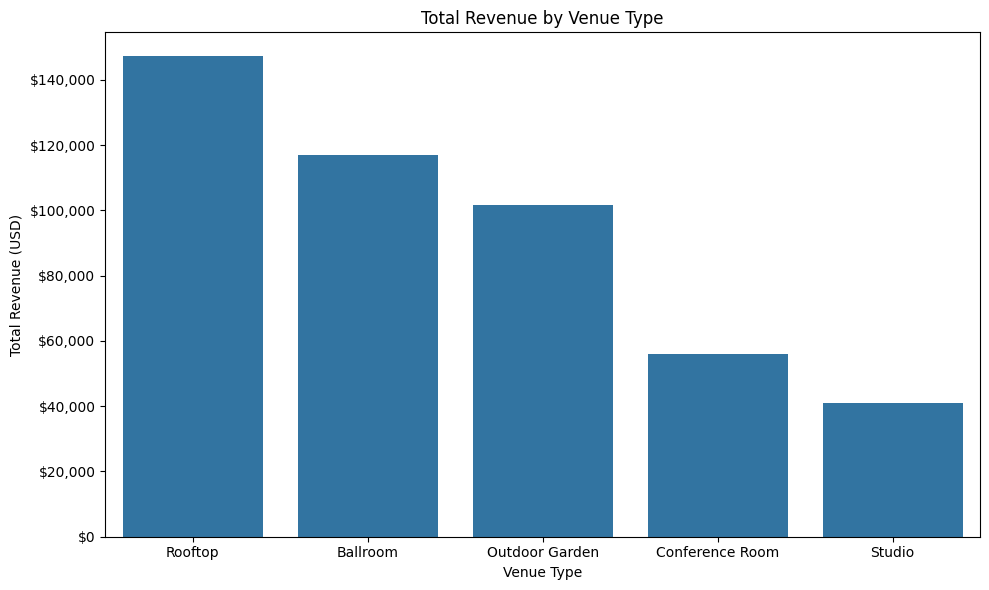

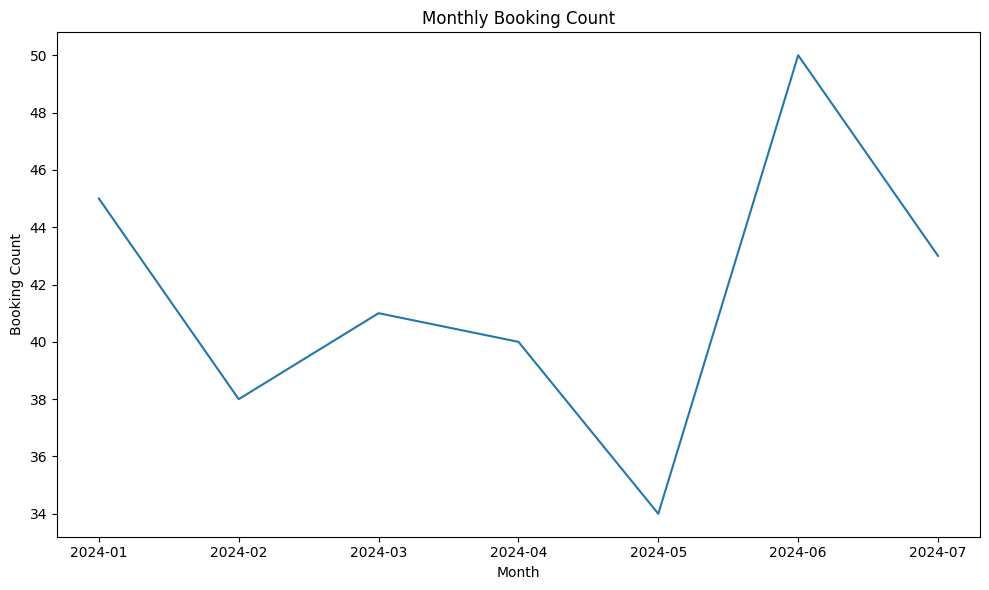

In [69]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: total revenue by venue_type (bar)
fig, ax = plt.subplots(figsize=(10, 6))
data = merge_venue_bookings.groupby('venue_type')['total_cost'].sum().sort_values(ascending=False)
sns.barplot(x=data.index, y=data.values, ax=ax, estimator=sum, errorbar=None)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Total Revenue by Venue Type')
ax.set_xlabel('Venue Type')
ax.set_ylabel('Total Revenue (USD)')
plt.tight_layout()
plt.show()

# Chart 2: monthly booking count (line)
dated = merge_venue_bookings.dropna(subset=['event_date'])
monthly = dated.groupby(dated['event_date'].dt.to_period('M'))['booking_id'].count()
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x=monthly.index.astype(str), y=monthly.values, ax=ax)
ax.set_title('Monthly Booking Count')
ax.set_xlabel('Month')
ax.set_ylabel('Booking Count')
plt.tight_layout()
plt.show()

---
# 💼 Business Insights
*What did I discover?*

- Rooftop leads rental revenue at **$147,213**. Studio is last at **$41,120**, which is **$106,093** less.  
  (Rooftop 매출이 $147,213으로 1위. Studio는 $41,120으로 맨 아래이고 차이는 $106,093)
- The average reservation is **6.04** hours.  
  (예약당 평균 대여시간은 6.04시간)
- Executive Suite and Willow Court are tied for most bookings, at **18** each.  
  (Executive Suite와 Willow Court가 18건으로 가장 많이 예약됨)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Keep Rooftop as the main revenue type. It is **$30,300** above Ballroom and **$106,093** above Studio.  
   (Rooftop을 핵심 매출 유형으로 둘 것. Ballroom보다 $30,300, Studio보다 $106,093 많음)
2. Staff and turnover plans can use **6.04** hours as the average booking length.  
   (인력과 회전 계획에는 평균 대여시간 6.04시간을 쓸 것)
3. Name both Executive Suite and Willow Court when reporting the busiest venue. Each has **18** bookings, one ahead of Panorama Roof at **17**.  
   (가장 바쁜 장소를 볼 때 Executive Suite와 Willow Court를 같이 적을 것. 둘 다 18건이고, Panorama Roof 17건보다 1건 많음)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- I almost dropped every row missing `event_date` or `total_cost`. That would change the hours average and the booking counts.  
  (`event_date`나 `total_cost`가 비어 있는 행을 통째로 지울 뻔했음. 그렇게 하면 평균 대여시간과 예약 횟수가 바뀜)
- Chart 2 passed a monthly `Period` straight into `sns.lineplot`, and the cell raised `TypeError`.  
  (차트 2에서 월 `Period`를 `sns.lineplot`에 그대로 넣어서 `TypeError`가 남)
- Q3 used `idxmax()` on `venue_type` and on `venue_name`, so it printed Rooftop and only Executive Suite. The **18**–**18** tie stayed hidden.  
  (Q3에서 `venue_type`과 `venue_name`에 `idxmax()`를 써서 Rooftop과 Executive Suite만 나왔음. 18건 동점이 안 보였음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `sum` skips missing `total_cost`, so those rows can stay for the hours average and the venue counts. Missing `event_date` is dropped only on the monthly chart.  
  (`sum`은 비어 있는 `total_cost`를 빼고 더함. 그 행은 평균 시간과 장소별 횟수에 남김. 비어 있는 `event_date`는 월별 차트에서만 뺌)
- A blank `venue_type` is not filled from the venue above or below. Those two venues stay out of the type revenue table.  
  (비어 있는 `venue_type`은 위아래 장소로 채우지 않음. 그 두 장소는 유형별 매출 표에 안 들어감)
- `value_counts()` shows the tie and the count. `idxmax()` returns one label and hides the count. A `Period` month has to become text before `sns.lineplot`.  
  (`value_counts()`는 동점과 횟수를 보여 줌. `idxmax()`는 이름 하나만 주고 횟수는 숨김. 월 `Period`는 `sns.lineplot` 전에 문자열로 바꿔야 함)  

---
# 🧠 Reflection

**What was difficult?**  
Deciding whether missing cost, missing date, and two blank venue types should be dropped or filled.  
(비어 있는 금액, 비어 있는 날짜, 유형이 빈 두 장소를 지울지 채울지 정하는 것)

**Why?**  
A missing cost is not a recorded dollar amount, a missing date cannot sit on a month, and the row above is not that venue's type.  
(빈 금액은 기록된 매출이 아니고, 빈 날짜는 어느 달에도 못 넣고, 위 행은 그 장소의 유형이 아님)

**How did I solve it?**  
Kept those rows for hours and booking counts, summed only recorded costs, and left the two types blank. The monthly line uses rows with a date, with the month as text.  
(시간과 예약 횟수에는 행을 남기고, 매출은 기록된 금액만 더함. 유형 두 칸은 비워 둠. 월별 선은 날짜가 있는 행만 쓰고, 월은 문자열로 넣음)

**What would I do differently next time?**  
Print the full `value_counts()` before using `idxmax()`, and do not fill a blank category from the neighboring row.  
(`idxmax()` 전에 `value_counts()` 전체를 보고, 빈 유형은 옆 행으로 채우지 않기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
The revenue ranking, the **6.04**-hour average, and the **18**–**18** tie are clear. A blank type still needs a recorded source before it is filled.  
(매출 순위, 평균 6.04시간, 18건 동점은 이해함. 빈 유형은 기록이 있어야 채움)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★★☆☆☆☆  
Cleaning text and merging were familiar. The hard part was which missing values to drop.  
(텍스트 정제와 병합은 익숙함. 어려운 부분은 어떤 결측을 지울지였음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 41 — capstone 1, customer segmentation with RFM (Round 3/3)  
  (RFM으로 고객 세분화하는 캡스톤)  